# 02 · Modelagem

O objetivo aqui é prever, para cada aluno do 2º ano da rede pública, a chance de ele
não se alfabetizar em 2024, usando só informações que já existiam antes da prova.

O treino completo (comparar modelos, ajustar hiperparâmetros, escolher o final) leva
uns 10 minutos, então fica no script `src/pipeline.py`, que salva o modelo em `models/` e as
tabelas e gráficos em `reports/` e `images/`. Este notebook carrega o que o script salvou,
mostra cada etapa e confere o modelo final no teste.

In [1]:
import sys
import json
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import joblib
import numpy as np
import pandas as pd
from IPython.display import Image, display
from sklearn import set_config

from src import config as C
from src.data import carregar as L
from src.evaluation import metricas as M
from src.modeling import treino
from src.preprocessing import base_analitica as B
from src.preprocessing.features import colunas_entrada, selecionar_features

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 40)
resultados = json.loads((C.DIR_REPORTS / "metricas.json").read_text(encoding="utf-8"))

def figura(nome, largura=850):
    display(Image(filename=str(C.DIR_IMAGENS / f"{nome}.png"), width=largura))

## 1. A base de treino

Cada linha é um aluno avaliado em 2024. Para cada um juntamos:

| Grupo | Exemplos | Ano |
|---|---|---|
| Escola | número de alunos matriculados no 2º ano | 2024 (cadastro, antes da prova) |
| Município e UF | taxa por rede, nota média, participação na prova | 2023 |
| Território | região, UF, mesorregião | fixo |
| Renda e contexto (IBGE) | PIB per capita, % urbana, adultos alfabetizados, esgoto | 2021-2022 |
| Escolas da rede (Inep) | nota do 5º ano, Ideb, Inse, tempo integral, alunos por turma | 2019-2023 |

O que não entra:
- qualquer coisa calculada a partir da prova de 2024 (taxa do ano, nota, quartil,
  distância até a meta). A Gold tem essas colunas, mas usá-las seria dar a resposta
  ao modelo;
- a meta do município. Ela é conhecida antes da prova, mas muda de lógica de um ano
  para o outro: a de 2024 foi calculada em cima do resultado de 2023 e a de 2025 não.
  Um modelo que aprendesse com a meta de 2024 erraria na de 2025. A meta só entra no
  notebook 04, na hora de comparar com a taxa prevista.

In [2]:
alunos = L.carregar_alunos()
indicador = L.carregar_indicador_municipio()
metas = L.carregar_metas_municipio()
ibge = L.carregar_ibge()

base = B.construir_base_aluno(alunos, indicador, metas, ibge,
                              L.carregar_censo_escolar(), L.carregar_atlas())
grupos = selecionar_features(base)
cols = colunas_entrada(grupos)
print(f"{len(base):,} alunos avaliados em {C.ANO_ALVO} | {len(cols)} variáveis de entrada")
for tipo, lista in grupos.items():
    print(f"  {tipo:20s} {len(lista):>2}  {lista}")

1,851,828 alunos avaliados em 2024 | 33 variáveis de entrada
  numericas            29  ['escola_matriculados', 'mun_taxa_rede_ant', 'mun_taxa_municipal_ant', 'mun_taxa_publica_ant', 'mun_media_ant', 'mun_participacao_ant', 'uf_taxa_ant', 'populacao', 'densidade', 'pib_per_capita', 'pct_va_agro', 'pct_urbana', 'taxa_alfab_adultos', 'pct_esgoto_adequado', 'inep_saeb5_lp_2023', 'inep_saeb5_lp_2021', 'inep_saeb5_lp_tendencia', 'inep_ideb_2023', 'inep_aprovacao_2ano_2023', 'inep_inse', 'inep_pct_inse_baixo', 'inep_pct_integral', 'inep_pct_biblioteca', 'inep_pct_internet_alunos', 'inep_pct_coordenador', 'inep_pct_material_infantil', 'inep_alunos_por_turma', 'inep_alunos_por_docente', 'inep_pct_rural']
  categoricas           3  ['nome_regiao', 'sigla_uf', 'rede_nome']
  alta_cardinalidade    1  ['nome_mesorregiao']


In [3]:
print("Colunas bloqueadas presentes na base:", set(base.columns) & set(C.COLUNAS_PROIBIDAS) - {C.ALVO})
print("Colunas bloqueadas entre as variáveis:", set(cols) & set(C.COLUNAS_PROIBIDAS))
base[cols].isna().mean().mul(100).sort_values(ascending=False).head(8).rename("% nulos").to_frame()

Colunas bloqueadas presentes na base: set()
Colunas bloqueadas entre as variáveis: set()


,% nulos
mun_participacao_ant,4.6696
inep_saeb5_lp_2021,2.4007
mun_taxa_municipal_ant,2.0175
mun_taxa_publica_ant,1.9145
mun_media_ant,1.9145
uf_taxa_ant,1.8567
mun_taxa_rede_ant,1.8567
inep_saeb5_lp_tendencia,0.9050


Os nulos vêm de municípios ou redes sem resultado em 2023 e de escolas que não estão
nos dados do Inep. Não preenchemos nada aqui: isso é feito dentro do pipeline, usando
só os dados de treino.

## 2. Separando treino e teste

Alunos da mesma cidade compartilham quase todas as informações de contexto. Se uma
cidade aparecesse no treino e no teste, o modelo seria testado em algo que já viu, e
o resultado sairia bom demais. Então separamos cidades inteiras:

- teste: 20% dos municípios, sorteados dentro de cada estado, guardados até o final;
- validação: dentro do treino, 5 rodadas, sempre deixando um grupo de municípios de
  fora (`StratifiedGroupKFold`). É com ela que comparamos modelos e ajustamos tudo.

In [4]:
divisao = pd.read_csv(C.DIR_PROCESSADO / "divisao_municipios.csv")
teste_ids = set(divisao.loc[divisao["conjunto"] == "teste", "id_municipio"])
treino_df = base[~base["id_municipio"].isin(teste_ids)].reset_index(drop=True)
teste_df = base[base["id_municipio"].isin(teste_ids)].reset_index(drop=True)
print(f"Treino: {len(treino_df):,} alunos em {treino_df['id_municipio'].nunique():,} municípios")
print(f"Teste : {len(teste_df):,} alunos em {teste_df['id_municipio'].nunique():,} municípios")
print("Municípios em comum:", len(set(treino_df["id_municipio"]) & set(teste_df["id_municipio"])))
pd.DataFrame({
    "treino": treino_df.groupby("nome_regiao", observed=True).size() / len(treino_df),
    "teste": teste_df.groupby("nome_regiao", observed=True).size() / len(teste_df),
}).style.format("{:.1%}")

Treino: 1,495,576 alunos em 4,416 municípios
Teste : 356,252 alunos em 1,101 municípios
Municípios em comum: 0


,treino,teste
nome_regiao,,
Centro-Oeste,7.7%,16.8%
Nordeste,24.8%,26.4%
Norte,11.0%,6.7%
Sudeste,41.8%,33.5%
Sul,14.7%,16.6%


## 3. O pipeline

Todo o tratamento dos dados fica dentro de um `Pipeline` do scikit-learn, junto com o
modelo. Assim o preenchimento de nulos, a padronização e a codificação são aprendidos
só com o treino e depois aplicados no teste. O diagrama abaixo é o modelo final:

1. `CriadorFeatures`: passa população, densidade, PIB per capita e tamanho da escola
   para logaritmo, porque são muito assimétricas;
2. numéricas: preenche nulos com a mediana e padroniza;
3. categóricas (região, UF, rede): preenche nulos e faz one-hot;
4. mesorregião: troca o nome pela taxa média da mesorregião (target encoding).

In [5]:
pacote = joblib.load(C.DIR_MODELOS / "modelo_aluno.joblib")
modelo, limiar = pacote["modelo"], pacote["limiar"]
print("Modelo final:", pacote["nome"])
set_config(display="diagram")
modelo

Modelo final: Regressão Logística


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessamento', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int8](2,)","[0,1]"
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('criar', ...), ('colunas', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value


## 4. Comparando modelos

Testamos cinco modelos com as mesmas rodadas de validação, numa amostra de 120 mil
alunos. Mostramos a AUC no treino e na validação: quando a do treino fica muito acima,
o modelo está decorando em vez de aprender.

In [6]:
comparacao = pd.read_csv(C.DIR_REPORTS / "comparacao_modelos.csv")
comparacao[["modelo", "roc_auc_media", "roc_auc_desvio", "pr_auc_media", "log_loss_media",
            "brier_media", "auc_treino_media", "gap_treino_valid", "segundos_media"]]

,modelo,roc_auc_media,roc_auc_desvio,pr_auc_media,log_loss_media,brier_media,auc_treino_media,gap_treino_valid,segundos_media
0,Regressão Logística,0.6589,0.0140,0.5527,0.6341,0.2224,0.6649,0.0060,2.7911
1,Random Forest,0.6568,0.0153,0.5469,0.6347,0.2227,0.6978,0.0410,7.9890
2,HistGradientBoosting,0.6556,0.0119,0.5467,0.6351,0.2230,0.6984,0.0428,8.7328
3,XGBoost,0.6541,0.0127,0.5446,0.6363,0.2235,0.7175,0.0634,6.4062
4,Baseline (proporção),0.5000,0.0000,0.4048,0.6749,0.2409,0.5000,0.0000,0.9695


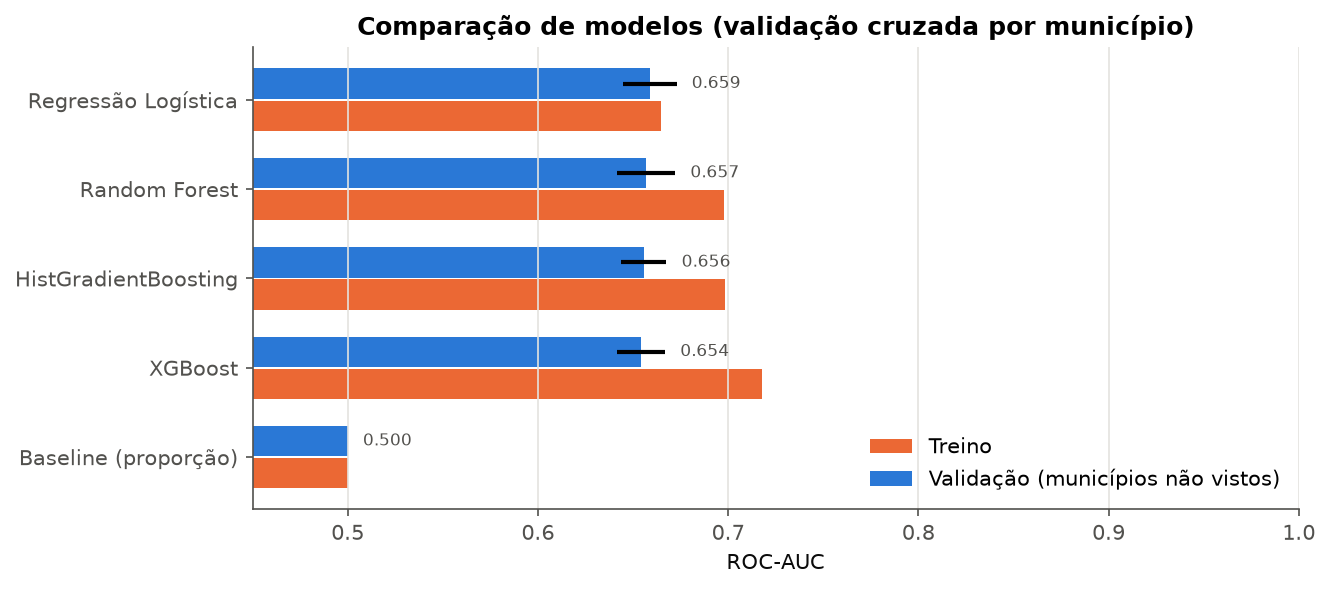

In [7]:
figura("modelo_comparacao")

Os modelos de árvore decoram: chegam a 0,70 a 0,72 no treino e ficam em 0,65 na
validação. A regressão logística quase não tem essa diferença (0,665 no treino, 0,659
na validação) e ainda fica na frente. Faz sentido: a relação nos dados é bem direta
(histórico pior, mais risco), e a flexibilidade das árvores acaba pegando ruído.

Antes de decidir, tentamos melhorar as árvores ajustando os hiperparâmetros.

## 5. Ajuste de hiperparâmetros com Optuna

O Optuna testa combinações de hiperparâmetros do XGBoost e vai aprendendo quais
regiões funcionam melhor. As tentativas que começam mal são interrompidas cedo, para
economizar tempo.

In [8]:
opt = resultados["optuna"]
print(f"Tentativas: {opt['tentativas']} ({opt['podadas']} interrompidas cedo)")
print(f"AUC XGBoost padrão   : {opt['auc_xgboost_padrao_cv']:.4f}")
print(f"AUC XGBoost ajustado : {opt['melhor_auc_cv']:.4f}")
pd.Series(opt["melhores_parametros"]).to_frame("valor")

Tentativas: 30 (17 interrompidas cedo)
AUC XGBoost padrão   : 0.6541
AUC XGBoost ajustado : 0.6590


,valor
n_estimators,500.0000
learning_rate,0.0183
max_depth,3.0000
min_child_weight,2.9031
subsample,0.6196
colsample_bytree,0.9399
reg_lambda,0.2083
reg_alpha,6.5974
gamma,3.0537


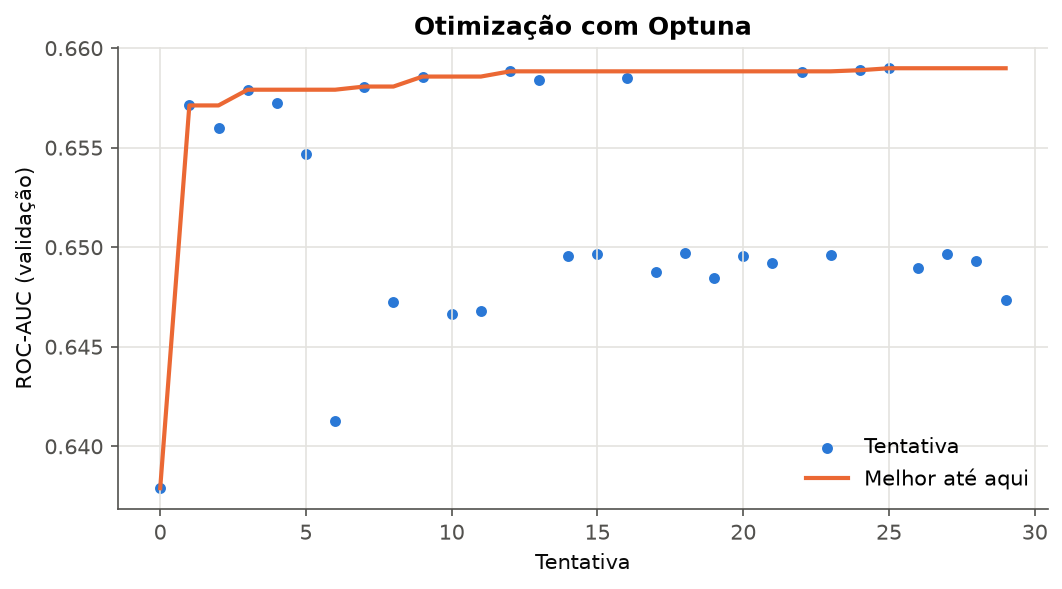

In [9]:
figura("modelo_optuna_historico", 650)

## 6. Mais dados ajudariam?

Treinamos com quantidades crescentes de alunos e medimos sempre nos mesmos municípios
de validação.

In [10]:
pd.DataFrame(resultados["curva_aprendizado"])

,n,auc_treino,auc_valid
0,2000,0.7310,0.6324
1,5000,0.7221,0.6398
2,15000,0.6972,0.6390
3,40000,0.6798,0.6475
4,100000,0.6751,0.6482
5,250000,0.6697,0.6484
6,400000,0.6691,0.6470


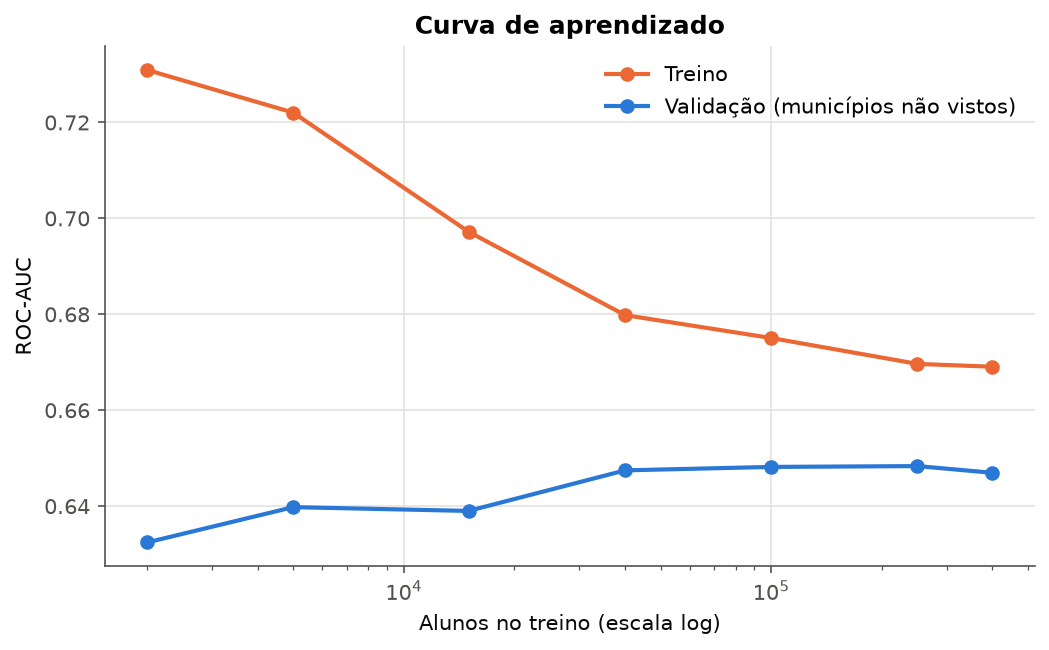

In [11]:
figura("modelo_curva_aprendizado", 650)

Com poucos alunos o modelo decora. A partir de uns 40 a 100 mil alunos, a validação
para de subir e fica em torno de 0,65. Ou seja, o limite não é a quantidade de dados,
e sim a informação disponível (lembrando que a escola explica só 17% da diferença
entre alunos). Usamos 400 mil alunos no treino final, bem acima desse ponto.

## 7. Escolhendo o modelo final

Comparamos o XGBoost ajustado com a regressão logística, agora com 400 mil alunos. O
limiar de decisão (a partir de que probabilidade consideramos o aluno "em risco")
também é escolhido aqui, na validação, e não no teste.

In [12]:
pd.DataFrame(resultados["selecao_final"]).T

,roc_auc,pr_auc,log_loss,brier,auc_treino,roc_auc_desvio
XGBoost otimizado,0.6564,0.5460,0.6355,0.2232,0.6683,0.0146
Regressão Logística,0.6579,0.5500,0.6349,0.2229,0.6630,0.0133


Os dois empatam: a diferença entre eles é menor que a variação entre as rodadas de
validação. Com empate, ficamos com o mais simples. Escolhemos a regressão logística
porque teve a média um pouco melhor, quase não decora e é fácil de explicar: cada
variável tem um peso, para mais ou para menos risco. O XGBoost continua aparecendo nos
resultados como comparação.

In [13]:
print("Modelo escolhido:", resultados["modelo_final"])
print(f"Limiar que maximiza o F1   : {resultados['limiar']['f1_max']:.3f}")
print(f"Limiar para encontrar 80% : {resultados['limiar']['recall_80']:.3f}")

Modelo escolhido: Regressão Logística
Limiar que maximiza o F1   : 0.291
Limiar para encontrar 80% : 0.344


## 8. Resultado no teste

Agora sim usamos os municípios que ficaram guardados desde o começo.

In [14]:
y_te, w_te = teste_df[C.ALVO].to_numpy(), teste_df[C.PESO].to_numpy()
p_te = modelo.predict_proba(teste_df[cols])[:, 1]

pd.DataFrame(resultados["teste"]).T.drop(columns=["roc_auc_ic95"], errors="ignore")[
    ["roc_auc", "pr_auc", "brier", "log_loss", "limiar", "precisao", "recall", "f1", "acuracia_balanceada"]]

,roc_auc,pr_auc,brier,log_loss,limiar,precisao,recall,f1,acuracia_balanceada
Regressão Logística,0.6646,0.5636,0.2236,0.6369,0.2908,0.4734,0.8776,0.6150,0.5921
Regressão Logística (limiar recall 80%),0.6646,0.5636,0.2236,0.6369,0.3436,0.5082,0.7260,0.5979,0.6135
XGBoost otimizado,0.6677,0.5655,0.2225,0.6344,0.2908,0.4705,0.8854,0.6145,0.5889
Baseline (proporção),0.5000,0.4152,0.2429,0.6789,0.2908,0.4152,1.0000,0.5868,0.5000


In [15]:
m = M.metricas_classificacao(y_te, p_te, w_te, limiar)
ic = resultados["teste"][resultados["modelo_final"]]["roc_auc_ic95"]
print(f"Conferindo neste notebook: AUC {m['roc_auc']:.4f}  (intervalo de 95%: {ic[0]:.4f} a {ic[1]:.4f})")
print(f"Recall {m['recall']:.3f} | precisão {m['precisao']:.3f} | F1 {m['f1']:.3f} | Brier {m['brier']:.4f}")

Conferindo neste notebook: AUC 0.6646  (intervalo de 95%: 0.6447 a 0.6820)
Recall 0.878 | precisão 0.473 | F1 0.615 | Brier 0.2236


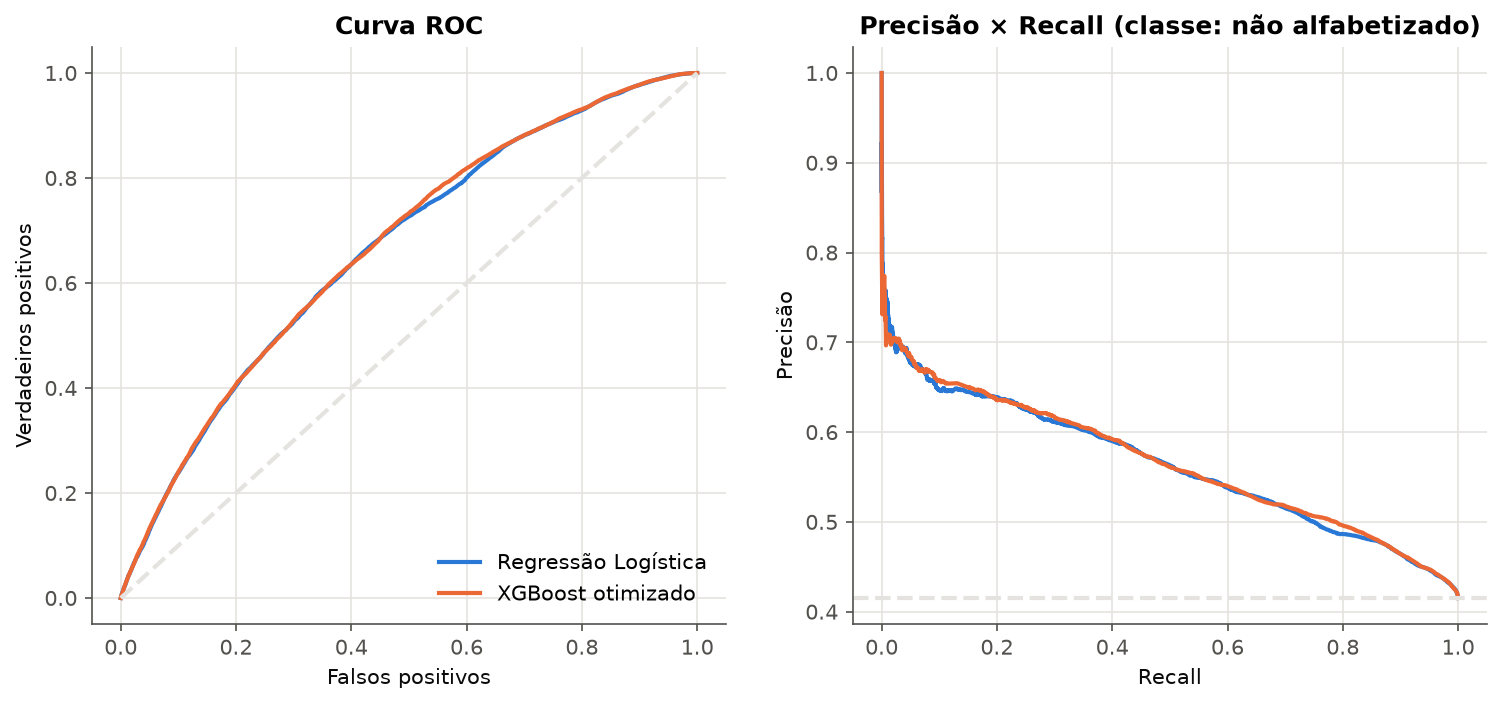

In [16]:
figura("modelo_curvas_roc_pr", 950)

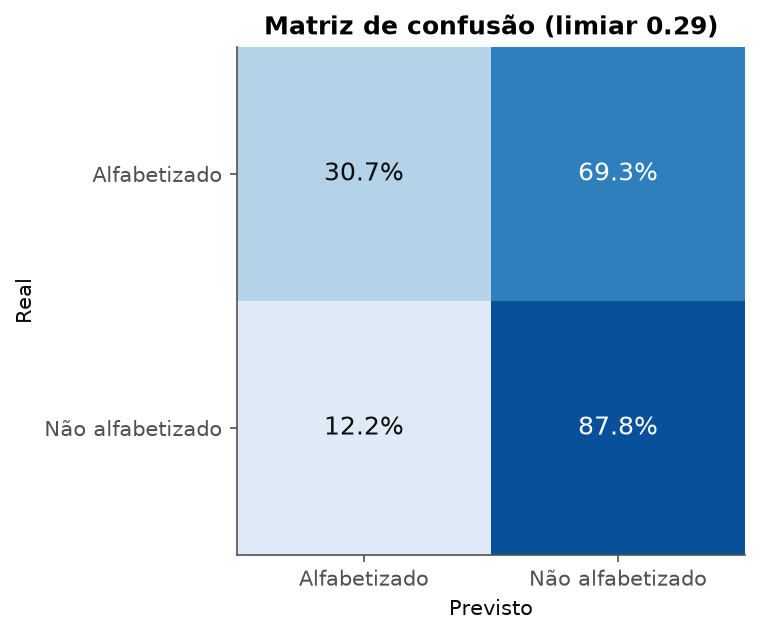

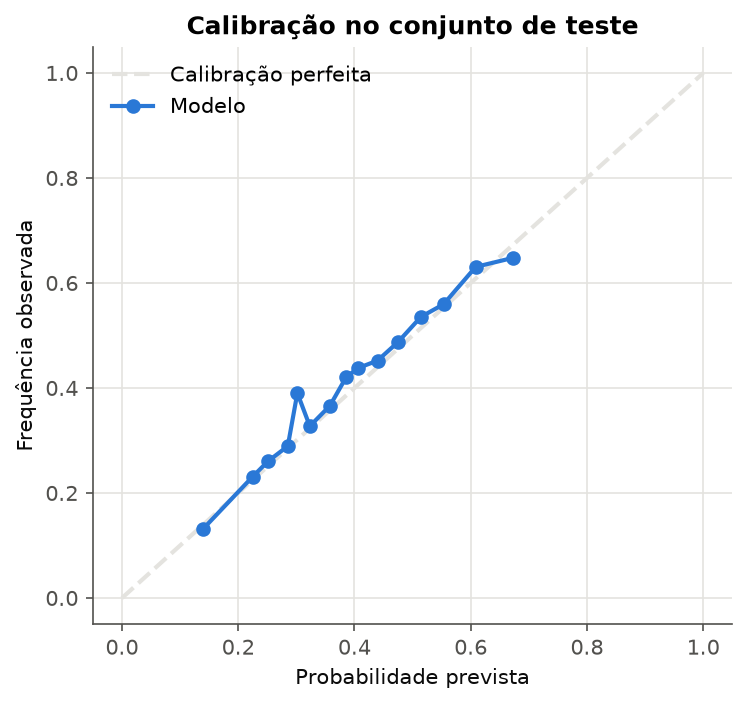

In [17]:
figura("modelo_matriz_confusao", 450)
figura("modelo_calibracao", 450)

## 9. Onde o modelo erra mais

,nome_regiao,alunos,taxa_nao_alfab_real,taxa_nao_alfab_prevista,roc_auc,recall,precisao,f1,brier
0,Centro-Oeste,59825,0.3720,0.3035,0.6072,0.7744,0.4305,0.5533,0.2317
1,Nordeste,94027,0.4570,0.4536,0.7077,0.9433,0.5286,0.6775,0.2140
2,Norte,23874,0.5162,0.5198,0.6275,0.9829,0.5256,0.6849,0.2365
3,Sudeste,119357,0.3973,0.3796,0.6447,0.8789,0.4434,0.5895,0.2253
4,Sul,59169,0.3950,0.3944,0.6627,0.8134,0.4605,0.5881,0.2210


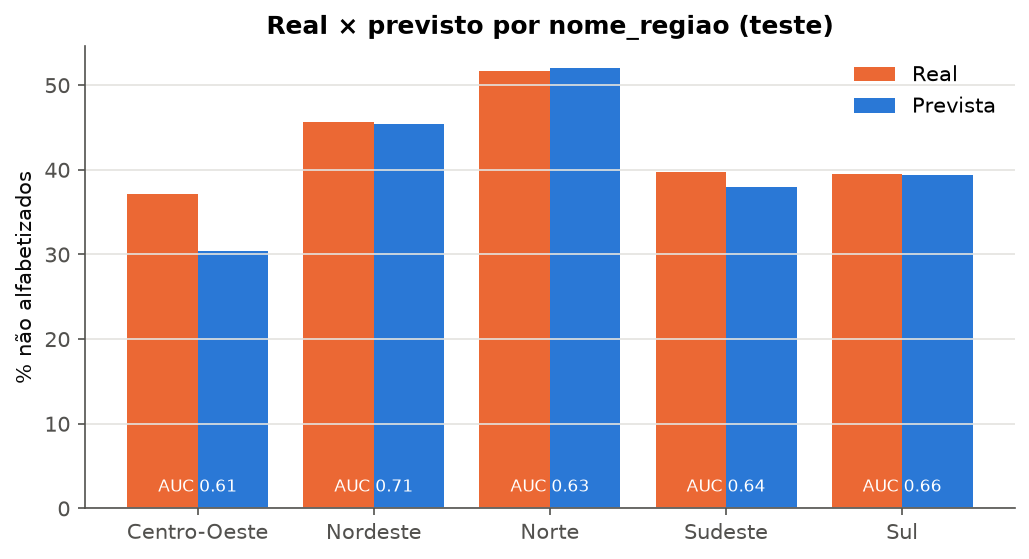

In [18]:
display(pd.read_csv(C.DIR_REPORTS / "desempenho_por_nome_regiao.csv"))
figura("modelo_desempenho_nome_regiao", 700)

In [19]:
display(pd.read_csv(C.DIR_REPORTS / "desempenho_por_rede_nome.csv"))

,rede_nome,alunos,taxa_nao_alfab_real,taxa_nao_alfab_prevista,roc_auc,recall,precisao,f1,brier
0,Estadual,52503,0.3788,0.3310,0.5842,0.8991,0.4109,0.5640,0.2311
1,Municipal,303749,0.4218,0.4088,0.6733,0.8741,0.4857,0.6244,0.2223


In [20]:
uf = M.metricas_por_segmento(
    teste_df[["sigla_uf", C.ALVO, C.PESO]].rename(columns={C.ALVO: "y", C.PESO: "peso"})
    .assign(proba=p_te), "sigla_uf", limiar=limiar)
uf.assign(erro_pp=100 * (uf["taxa_nao_alfab_prevista"] - uf["taxa_nao_alfab_real"])).sort_values("erro_pp").head(6)

,sigla_uf,alunos,taxa_nao_alfab_real,taxa_nao_alfab_prevista,roc_auc,recall,precisao,f1,brier,erro_pp
6,DF,22111,0.4087,0.3009,0.5289,1.0000,0.4087,0.5802,0.2532,-10.7743
12,MT,12866,0.4689,0.3959,0.5542,0.9730,0.4847,0.6471,0.2525,-7.2968
0,AC,1005,0.5705,0.5050,0.5893,1.0000,0.5705,0.7266,0.2434,-6.5580
3,AP,814,0.6062,0.5479,0.5256,1.0000,0.6062,0.7548,0.2431,-5.8266
8,GO,20137,0.2719,0.2318,0.5709,0.1219,0.3681,0.1832,0.1966,-4.0140
14,PB,5031,0.4429,0.4108,0.6638,0.9329,0.4986,0.6498,0.2257,-3.2089


## 10. O que os resultados mostram

A AUC no teste foi de 0,665 (com 95% de confiança, entre 0,645 e 0,682). O modelo
acerta bem mais que o acaso (0,50) e foi um pouco melhor no teste do que na validação,
então não há sinal de que ele esteja decorando.

O número parece baixo, mas tem um teto. Mesmo um modelo que soubesse o resultado real
de cada município em 2024 chegaria só a 0,669, e um que soubesse o de cada escola, a
0,709. O modelo funciona como um medidor de risco do contexto: ordena bem municípios
e escolas, mas não separa dois alunos da mesma turma. Os dados do Inep subiram a AUC
de 0,662 para 0,665; o ganho maior aparece no resultado por município (notebook 04).

Com o limiar escolhido, o modelo encontra 88% dos alunos que não se alfabetizam, e
cerca de metade dos alunos que ele aponta realmente não se alfabetizou. Para política
pública isso é aceitável: deixar uma criança em risco sem apoio custa mais do que
apoiar uma que não precisava. Se o recurso for curto, dá para usar o limiar de 80%.

As probabilidades estão bem calibradas (o gráfico de calibração segue a diagonal), e
isso permite somá-las para estimar a taxa de cada município.

O modelo vai melhor no Nordeste (AUC 0,71) e pior no Centro-Oeste (0,61) e na rede
estadual (0,58), onde subestima o risco em 5 a 7 pontos. Nos estados da tabela acima também
subestima. Nesses lugares, a lista de risco deve ser lida como um piso.